## Mecanismo de transmisión de la política monetaria y su impacto en las finanzas públicas de México
### Análisis exploratorio del dataset integrado

**Fuentes:** 
* Tasa de Interés Interbancaria de Equilibrio del Banco de México (TIIE)
* Deuda Pública de la Secretaría de Hacienda y Crédito Público (SHCP)
* Ingresos, Gastos y Financiamiento del Sector Público de la Secretaría de Hacienda y Crédito Público (SHCP)
* Indicador Global de la Actividad Económica del Instituto Nacional de Estadística y Geografía (IGAE - INEGI)
* Índice Nacional de Precios al Consumidor del Instituto Nacional de Estadística y Geografía (INPC - INEGI)

**Objetivo:**
Explorar y graficar series de tiempo macroeconómicas (2011-2026) para evaluar cuantitativamente el mecanismo de transmisión de la política monetaria en México, determinando los rezagos temporales y los efectos de los cambios en las tasas de interés sobre la inflación (INPC), el crecimiento económico (IGAE) y las finanzas públicas (ingresos y gastos de la SHCP).


### 0. Configuración

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

# Ajusta la ruta según la ubicación del notebook (aquí se asume notebooks/ en la raíz del repo)
PARQUET_PATH = Path("../data/processed/NOMBRE_DEL_ARCHIVO.parquet")  # TODO: cambiar nombre

### 1. Introducción

In [2]:
### PONER CÓDIGO

### 2.

In [3]:
### PONER CÓDIGO

### 3. Pregunta Mauricio

In [4]:
### PONER CÓDIGO

### 4. Pregunta Analítica 2
> **¿Ha sido la tasa de interés real positiva en México entre 2012 y 2026, y reacciona la TIIE a la inflación medida con el INPC?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Nivel:** comparando la TIIE con la inflación anual, ¿qué tan seguido y por cuánto la tasa real (TIIE menos inflación) fue negativa?
2. **Reacción:** ¿se mueve la TIIE junto con la inflación o después de ella? ¿con cuántos meses de rezago?

**Por qué importa:** una tasa real negativa significa que el dinero prestado se abarata en términos de poder adquisitivo, lo que afecta ahorradores, deudores y el costo real del financiamiento público.

In [5]:
spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_INPC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

# Rutas candidatas, de la más a la menos preferida. Ajusta la primera si el
# Parquet integrado del pipeline tiene otro nombre en tu repositorio.
CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]  # por si el notebook está en notebooks/

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Sólo se necesitan tres columnas para esta pregunta.
macro = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("VALOR_INPC").cast("double").alias("VALOR_INPC"),
)
macro.createOrReplaceTempView("macro")

print(f"[FUENTE] {ruta}")
macro.printSchema()
macro.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- VALOR_INPC: double (nullable = true)

+-------+------------------+---------------+
|  CICLO|              TIIE|     VALOR_INPC|
+-------+------------------+---------------+
|2011-01|4.5495238095238095|75.295991345634|
|2011-02| 4.518421052631578|75.578460244005|
|2011-03| 4.488636363636363|75.723450928541|
|2011-04| 4.504736842105263| 75.71744095198|
|2011-05| 4.466363636363637|75.159264378869|
+-------+------------------+---------------+
only showing top 5 rows



## 4.1. Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado`: dataset integrado por el pipeline PySpark a partir de las fuentes del proyecto (deuda, finanzas públicas, IGAE, TIIE e INPC). |
| **Columnas usadas** | `CICLO` (mes, texto `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `VALOR_INPC` (nivel del índice nacional de precios al consumidor). |
| **Periodo cubierto** | Se calcula en la celda siguiente (de enero de 2011 a junio de 2026 en la versión actual). |
| **Granularidad** | Una fila por mes, sin cortes por actividad ni por región. |

Antes de consultar se comprueban las condiciones que la pregunta necesita: sin nulos en las dos columnas, sin meses repetidos y sin huecos en la serie. Esto último importa porque el cálculo de inflación anual compara cada mes con el de 12 filas atrás.

In [6]:
resumen = spark.sql("""
    SELECT COUNT(*)                AS FILAS,
           COUNT(DISTINCT CICLO)   AS MESES_DISTINTOS,
           MIN(CICLO)              AS PRIMER_MES,
           MAX(CICLO)              AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)       AS NULOS_TIIE,
           SUM(CASE WHEN VALOR_INPC IS NULL THEN 1 ELSE 0 END) AS NULOS_INPC
    FROM macro
""").first()

meses_esperados = (
    (int(resumen.ULTIMO_MES[:4]) - int(resumen.PRIMER_MES[:4])) * 12
    + int(resumen.ULTIMO_MES[5:7]) - int(resumen.PRIMER_MES[5:7]) + 1
)

assert resumen.NULOS_TIIE == 0 and resumen.NULOS_INPC == 0, "Hay nulos en TIIE o VALOR_INPC"
assert resumen.FILAS == resumen.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen.FILAS == meses_esperados, f"Hay huecos: {resumen.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen.PRIMER_MES} a {resumen.ULTIMO_MES} | {resumen.FILAS} meses | validaciones OK")

Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


## 4.2. Consultas de consumo (Spark SQL)

### Qué se calcula una vez en el pipeline y qué se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Unión de fuentes, limpieza, `CICLO` mensual, `TIIE`, `VALOR_INPC` | **Pipeline (ya preparado)** | Se consume tal cual; no se reprocesa. |
| Inflación anual a partir del INPC | **Consulta 1 (al consultar)** | Depende de la definición elegida para esta pregunta (variación contra el mismo mes del año anterior). |
| Tasa real y marca de tasa real negativa | **Consulta 1 (al consultar)** | Derivada de la inflación anual. |
| Resumen anual | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista de la consulta 1. |
| Correlaciones con rezago | **Consulta 3 (al consultar)** | Se recalcula con cada rezago que se pruebe. |

Si el equipo decide que la inflación anual se usará en otras preguntas, puede moverse al ETL (`enrich.py`) en una iteración posterior; por ahora se mantiene en la capa de consumo para no tocar el pipeline.

### Consulta 1 — Inflación anual y tasa real

In [7]:
tasa_real = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               VALOR_INPC,
               ROUND((VALOR_INPC / LAG(VALOR_INPC, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS INFLACION_ANUAL
        FROM macro
    )
    SELECT CICLO,
           TIIE,
           VALOR_INPC,
           INFLACION_ANUAL,
           ROUND(TIIE - INFLACION_ANUAL, 4)                         AS TASA_REAL,
           CASE WHEN TIIE - INFLACION_ANUAL < 0 THEN 1 ELSE 0 END   AS TASA_REAL_NEGATIVA
    FROM base
    WHERE INFLACION_ANUAL IS NOT NULL      -- los primeros 12 meses no tienen mes comparable
    ORDER BY CICLO
""")
tasa_real.createOrReplaceTempView("tasa_real")
tasa_real.cache()

print(f"Filas con inflación anual calculable: {tasa_real.count()}")
tasa_real.show(5)
tasa_real.orderBy(F.col("CICLO").desc()).show(3)

Filas con inflación anual calculable: 174
+-------+------------------+---------------+---------------+---------+------------------+
|  CICLO|              TIIE|     VALOR_INPC|INFLACION_ANUAL|TASA_REAL|TASA_REAL_NEGATIVA|
+-------+------------------+---------------+---------------+---------+------------------+
|2012-01|4.4790909090909095|78.343049462107|         4.0468|   0.4323|                 0|
|2012-02|             4.497|78.502313840976|         3.8686|   0.6284|                 0|
|2012-03| 4.497619047619048|78.547388665184|         3.7293|   0.7683|                 0|
|2012-04| 4.483157894736842|78.300979626179|         3.4121|   1.0711|                 0|
|2012-05| 4.505454545454546|78.053819340105|         3.8512|   0.6543|                 0|
+-------+------------------+---------------+---------------+---------+------------------+
only showing top 5 rows

+-------+-----------------+----------+---------------+---------+------------------+
|  CICLO|             TIIE|VALOR_INPC|I

### Consulta 2 — Resumen por año

In [8]:
por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)              AS ANIO,
           COUNT(*)                         AS MESES,
           ROUND(AVG(TIIE), 2)              AS TIIE_PROM,
           ROUND(AVG(INFLACION_ANUAL), 2)   AS INFLACION_PROM,
           ROUND(AVG(TASA_REAL), 2)         AS TASA_REAL_PROM,
           SUM(TASA_REAL_NEGATIVA)          AS MESES_TASA_REAL_NEG
    FROM tasa_real
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
por_anio.show(20)

+----+-----+---------+--------------+--------------+-------------------+
|ANIO|MESES|TIIE_PROM|INFLACION_PROM|TASA_REAL_PROM|MESES_TASA_REAL_NEG|
+----+-----+---------+--------------+--------------+-------------------+
|2012|   12|      4.5|          4.11|          0.38|                  3|
|2013|   12|     3.99|          3.81|          0.19|                  6|
|2014|   12|     3.25|          4.02|         -0.77|                 10|
|2015|   12|     3.08|          2.72|          0.35|                  3|
|2016|   12|     4.18|          2.82|          1.36|                  0|
|2017|   12|     6.73|          6.04|          0.69|                  0|
|2018|   12|      7.7|           4.9|           2.8|                  0|
|2019|   12|     8.09|          3.64|          4.45|                  0|
|2020|   12|     5.49|           3.4|           2.1|                  0|
|2021|   12|     4.39|          5.68|         -1.29|                 10|
|2022|   12|     7.64|          7.89|         -0.25

### Consulta 3 — ¿La TIIE sigue a la inflación? Correlación con rezagos

Se correlaciona la inflación anual de un mes con la TIIE de `k` meses después. Si la TIIE reaccionara de inmediato, la correlación más alta estaría en `k = 0`; si reacciona con retraso, crecerá al aumentar `k`.

In [9]:
REZAGOS = [0, 3, 6, 9, 12]
partes = []
for k in REZAGOS:
    tiie_futura = "TIIE" if k == 0 else f"LEAD(TIIE, {k}) OVER (ORDER BY CICLO)"
    partes.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(INFLACION_ANUAL, TIIE_FUTURA), 4) AS CORRELACION
        FROM (SELECT INFLACION_ANUAL, {tiie_futura} AS TIIE_FUTURA FROM tasa_real)
        WHERE TIIE_FUTURA IS NOT NULL
    """)

rezagos_df = spark.sql(" UNION ALL ".join(partes)).orderBy("REZAGO_MESES")
rezagos_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|     0.3844|
|           3|    171|     0.5122|
|           6|    168|     0.6096|
|           9|    165|     0.6806|
|          12|    162|     0.7216|
+------------+-------+-----------+



## 4.3. Indicadores y hallazgos

La celda siguiente recoge los resultados de Spark en pandas (son pocas filas) y calcula los indicadores directamente desde ellos, de modo que los números del texto siempre se pueden verificar.

In [10]:
pdf = tasa_real.toPandas()
anual = por_anio.toPandas()
corr = rezagos_df.toPandas()

n = len(pdf)
neg = int(pdf["TASA_REAL_NEGATIVA"].sum())
fila_min = pdf.loc[pdf["TASA_REAL"].idxmin()]
fila_max = pdf.loc[pdf["TASA_REAL"].idxmax()]
mejor = corr.loc[corr["CORRELACION"].idxmax()]
corr0 = float(corr.loc[corr["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])

print("INDICADOR 1 · Nivel de la tasa real")
print(f"  Tasa real promedio: {pdf['TASA_REAL'].mean():.2f} pp ({pdf['CICLO'].iloc[0]} a {pdf['CICLO'].iloc[-1]})")
print(f"  Meses con tasa real negativa: {neg} de {n} ({neg / n:.1%})")
print(f"  Mínimo: {fila_min['TASA_REAL']:.2f} pp en {fila_min['CICLO']} (TIIE {fila_min['TIIE']:.2f}%, inflación {fila_min['INFLACION_ANUAL']:.2f}%)")
print(f"  Máximo: {fila_max['TASA_REAL']:.2f} pp en {fila_max['CICLO']} (TIIE {fila_max['TIIE']:.2f}%, inflación {fila_max['INFLACION_ANUAL']:.2f}%)")
print()
print("INDICADOR 2 · Reacción de la TIIE a la inflación")
print(f"  Correlación sin rezago: {corr0:.2f}")
print(f"  Correlación más alta: {mejor['CORRELACION']:.2f} con TIIE {int(mejor['REZAGO_MESES'])} meses después")

INDICADOR 1 · Nivel de la tasa real
  Tasa real promedio: 1.91 pp (2012-01 a 2026-06)
  Meses con tasa real negativa: 41 de 174 (23.6%)
  Mínimo: -2.46 pp en 2021-11 (TIIE 4.91%, inflación 7.37%)
  Máximo: 7.00 pp en 2023-10 (TIIE 11.25%, inflación 4.26%)

INDICADOR 2 · Reacción de la TIIE a la inflación
  Correlación sin rezago: 0.38
  Correlación más alta: 0.72 con TIIE 12 meses después


### Hallazgos (con la corrida de referencia, datos de 2011-01 a 2026-06)

**Hallazgo 1 — La tasa real fue positiva la mayor parte del tiempo, pero con episodios claros de tasa negativa.**
De los 174 meses con inflación anual calculable (2012-01 a 2026-06), 41 (23.6%) tuvieron tasa real negativa y el promedio fue de 1.91 puntos porcentuales. Los meses negativos se concentran en 2013–2014 y en 2021–2022; el mínimo fue de −2.46 pp en noviembre de 2021 (TIIE 4.91% frente a inflación de 7.37%). En el extremo opuesto, la tasa real llegó a 7.00 pp en octubre de 2023, con una TIIE cercana a 11.25% y una inflación de 4.26%.

**Hallazgo 2 — La TIIE reacciona a la inflación con retraso, no de inmediato.**
La correlación entre la inflación de un mes y la TIIE del mismo mes es de 0.38, pero sube de forma sostenida con el rezago: 0.51 a 3 meses, 0.61 a 6, 0.68 a 9 y 0.72 a 12 meses. Esto es coherente con una política monetaria que responde a la inflación ya observada. El ciclo 2021–2023 lo ilustra: la inflación se aceleró desde 2021, la tasa real fue negativa mientras la TIIE seguía baja, y la TIIE alcanzó su máximo de 11.29% hasta mayo de 2023.

**Lectura reciente.** Con la información disponible hasta junio de 2026, la TIIE (6.48%) se encuentra por encima de la inflación anual (3.37%), con una tasa real de alrededor de 3.1 pp.

> Los valores se recalculan en la celda anterior; si el dataset cambia, estos párrafos deben actualizarse.

## 4.4. Visualización

El primer panel muestra la TIIE frente a la inflación anual; el área roja marca los meses en que la inflación estuvo por encima de la TIIE (tasa real negativa). El segundo muestra la tasa real mes a mes.

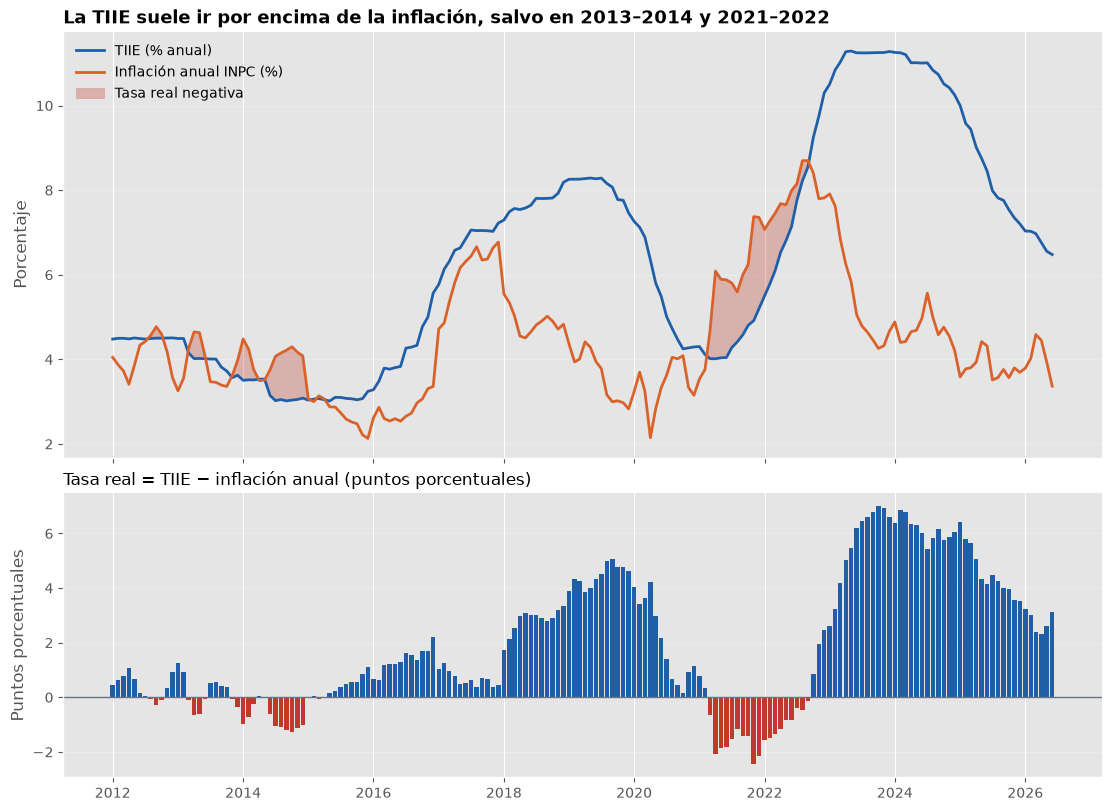

In [11]:
import os
os.makedirs("../docs/pregunta2", exist_ok=True)

AZUL, NARANJA, ROJO, GRIS = "#1F5FA8", "#D9622B", "#C0392B", "#6B7280"

pdf["FECHA"] = pd.to_datetime(pdf["CICLO"] + "-01")
neg_mask = (pdf["TASA_REAL"] < 0).to_numpy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
                               gridspec_kw={"height_ratios": [3, 2]})

# Panel 1: TIIE vs inflación anual
ax1.plot(pdf["FECHA"], pdf["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.plot(pdf["FECHA"], pdf["INFLACION_ANUAL"], color=NARANJA, lw=2, label="Inflación anual INPC (%)")
ax1.fill_between(pdf["FECHA"], pdf["TIIE"], pdf["INFLACION_ANUAL"], where=neg_mask,
                 interpolate=True, color=ROJO, alpha=0.30, label="Tasa real negativa")
ax1.set_title("La TIIE suele ir por encima de la inflación, salvo en 2013–2014 y 2021–2022", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("Porcentaje")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: tasa real
colores = [ROJO if v < 0 else AZUL for v in pdf["TASA_REAL"]]
ax2.bar(pdf["FECHA"], pdf["TASA_REAL"], width=25, color=colores)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Tasa real = TIIE − inflación anual (puntos porcentuales)", loc="left", fontsize=12)
ax2.set_ylabel("Puntos porcentuales")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta2/tiie_inpc_tasa_real.png", dpi=150)
plt.show()

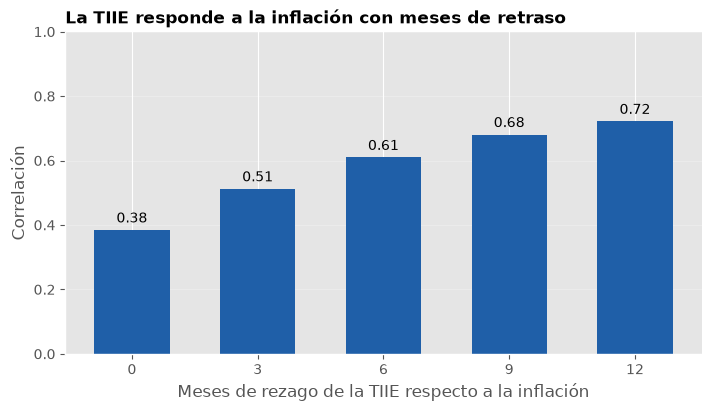

In [12]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
barras = ax.bar(corr["REZAGO_MESES"].astype(str), corr["CORRELACION"], color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_ylim(0, 1)
ax.set_title("La TIIE responde a la inflación con meses de retraso", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago de la TIIE respecto a la inflación")
ax.set_ylabel("Correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta2/tiie_inflacion_rezagos.png", dpi=150)
plt.show()

## 4.5 Limitaciones e interpretación prudente

- **Tasa real ex post.** Se compara la TIIE con la inflación que efectivamente ocurrió, no con la inflación que los agentes esperaban al fijar la tasa. Una tasa real "negativa" en el cálculo no implica que fuera negativa ex ante.
- **Correlación no es causalidad.** Que la TIIE siga a la inflación con rezago es consistente con una política monetaria reactiva, pero con una sola serie mensual no se puede aislar el efecto de la tasa sobre la inflación ni de otros factores (tipo de cambio, choques externos, expectativas).
- **Series con tendencia.** Las correlaciones entre series persistentes pueden inflarse por comovimientos largos; deben leerse como indicio descriptivo, no como estimación de un efecto.
- **Cobertura temporal.** Los datos van de 2011-01 a 2026-06. La inflación anual necesita 12 meses previos, por lo que el análisis de tasa real comienza en 2012-01 y los resultados dependen de los ciclos que caen en esa ventana.
- **Definición de las variables.** `TIIE` se toma como viene en el dataset (promedio mensual, según los decimales que presenta) y `VALOR_INPC` como nivel del índice; conviene confirmar con la documentación de la fuente el plazo de la TIIE y la base del INPC antes de publicar conclusiones.
- **Alcance.** Este bloque no incorpora deuda, ingresos ni gasto públicos; cualquier afirmación sobre su relación con la tasa real corresponde a otras preguntas del equipo.

## 8. Arquitectura aplicada (Etapa D)

Recorrido de los datos en el proyecto y lugar de este notebook:

```text
 Fuentes (CSV en data/raw)        Procesamiento             Almacenamiento            Consulta               Resultado
┌─────────────────────────┐     ┌────────────────┐        ┌──────────────────┐     ┌────────────────┐     ┌───────────────────────┐
│ deuda, finanzas, IGAE,  │ ──▶ │ PySpark (src/) │  ───▶  │ Parquet integrado│ ──▶ │ Spark SQL en   │ ──▶ │ Tablas e indicadores  │
│ TIIE, INPC              │     │ extract, clean,│        │ (data/processed) │     │ este notebook  │     │ + gráficas en         │
│                         │     │ validate, load │        │ mensual (CICLO)  │     │ (vistas tasa_  │     │ ..docs/pregunta2/     │
└─────────────────────────┘     └────────────────┘        └──────────────────┘     │ real, macro)   │     └───────────────────────┘
                                                                                    └────────────────┘
```

**Dónde se almacenan y cómo se reutilizan.** El pipeline deja el dataset integrado en formato Parquet, en disco local. El notebook lo lee con Spark, registra vistas temporales (`macro`, `tasa_real`) y ejecuta las consultas sin reescribir el dato base. Las vistas viven sólo mientras dura la sesión de Spark; lo que se conserva es el Parquet y las figuras guardadas en `..docs/pregunta2/`.

**Implementado hoy:** lectura de Parquet/CSV, consultas Spark SQL sobre vistas temporales y gráficas con matplotlib.
**Posible evolución (no implementada):** publicar la tabla de resultados en un Data Lake o Lakehouse con tablas versionadas, o mover la inflación anual y la tasa real al ETL si más preguntas las necesitan.

**Cómo se incorporarían nuevos datos o correcciones.** Se agregarían los meses nuevos a las fuentes de `data/raw` (o se corregiría el valor erróneo), se volvería a ejecutar el pipeline para regenerar el Parquet y se reejecutaría este notebook de arriba abajo. Las validaciones de la sección 2 detectan meses repetidos, huecos o nulos antes de calcular. No se implementa carga incremental porque el volumen (unos 186 registros) no la justifica.

### Cómo reproducir
1. Ejecutar el pipeline para generar el Parquet integrado (o dejar `macro_finanzas_consolidado.csv` en `data/raw/`).
2. Abrir este notebook desde la raíz del repositorio (o desde `notebooks/`) con PySpark, pandas y matplotlib instalados.
3. Ejecutar todas las celdas en orden. Las figuras se guardan en `..docs/pregunta2/`.

### 5. Pregunta Analítica 3  
**¿En qué medida los incrementos en la Tasa de Interés Interbancaria de Equilibrio (TIIE) frenan el dinamismo de la actividad económica medida por el Indicador Global de la Actividad Económica (IGAE) entre 2012 y 2026, y con cuántos meses de rezago se manifiesta este enfriamiento?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Comportamiento por régimen monetario:** Comparando el crecimiento anual del IGAE en periodos de política restrictiva (TIIE por encima de su mediana histórica) frente a periodos acomodaticios, ¿se desacelera efectivamente la actividad económica cuando sube el costo del dinero?
2. **Rezago de transmisión:** ¿El impacto de un movimiento en la TIIE sobre el crecimiento del IGAE ocurre de forma inmediata o con retraso? ¿en qué ventana de meses (`k = 0, 3, 6, 9, 12`) se observa la correlación negativa más marcada?

**Por qué importa:** El canal de tasas de interés sobre la actividad real (consumo e inversión) es el puente entre las decisiones de Banxico y las finanzas públicas, ya que una desaceleración del IGAE reduce la base gravable y la recaudación tributaria de la SHCP.

In [2]:
#Carga del archivo parquet y creación de vista en Spark
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")

spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_IGAE")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Selección de las tres columnas necesarias para esta pregunta
macro_igae = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("MONTO_IGAE_TOTAL").cast("double").alias("MONTO_IGAE_TOTAL"),
)
macro_igae.createOrReplaceTempView("macro_igae")

print(f"[FUENTE] {ruta}")
macro_igae.printSchema()
macro_igae.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- MONTO_IGAE_TOTAL: double (nullable = true)

+-------+------------------+----------------+
|  CICLO|              TIIE|MONTO_IGAE_TOTAL|
+-------+------------------+----------------+
|2011-01|4.5495238095238095|81.0595403368419|
|2011-02| 4.518421052631578|80.1156149128606|
|2011-03| 4.488636363636363|87.1736739506537|
|2011-04| 4.504736842105263| 82.957170328975|
|2011-05| 4.466363636363637|86.0386317656384|
+-------+------------------+----------------+
only showing top 5 rows



## 5.1. Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado.parquet`: Dataset maestro integrado por el pipeline PySpark a partir de las fuentes oficiales de Banxico, INEGI y SHCP. |
| **Columnas usadas** | `CICLO` (mes en formato `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `MONTO_IGAE_TOTAL` (nivel del Indicador Global de la Actividad Económica del INEGI). |
| **Periodo cubierto** | Enero de 2011 (`2011-01`) a junio de 2026 (`2026-06`), totalizando 186 observaciones mensuales (174 meses con variación anual calculable a partir de `2012-01`). |
| **Granularidad** | Mensual a nivel nacional (una fila única por ciclo `AAAA-MM`, sin desagregación sectorial ni estatal). |

Antes de ejecutar las consultas analíticas se valida que no existan valores nulos, meses duplicados ni saltos en la secuencia temporal, requisito indispensable para calcular correctamente los rezagos de 12 meses (`LAG(MONTO_IGAE_TOTAL, 12)`).

In [3]:
#Validación de calidad antes del consumo
resumen_igae = spark.sql("""
    SELECT COUNT(*)                                            AS FILAS,
           COUNT(DISTINCT CICLO)                               AS MESES_DISTINTOS,
           MIN(CICLO)                                          AS PRIMER_MES,
           MAX(CICLO)                                          AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)       AS NULOS_TIIE,
           SUM(CASE WHEN MONTO_IGAE_TOTAL IS NULL THEN 1 ELSE 0 END) AS NULOS_IGAE
    FROM macro_igae
""").first()

meses_esperados = (
    (int(resumen_igae.ULTIMO_MES[:4]) - int(resumen_igae.PRIMER_MES[:4])) * 12
    + int(resumen_igae.ULTIMO_MES[5:7]) - int(resumen_igae.PRIMER_MES[5:7]) + 1
)

assert resumen_igae.NULOS_TIIE == 0 and resumen_igae.NULOS_IGAE == 0, "Hay nulos en TIIE o MONTO_IGAE_TOTAL"
assert resumen_igae.FILAS == resumen_igae.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen_igae.FILAS == meses_esperados, f"Hay huecos: {resumen_igae.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen_igae.PRIMER_MES} a {resumen_igae.ULTIMO_MES} | {resumen_igae.FILAS} meses | validaciones OK")


Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


## 5.2. Consultas de consumo (Spark SQL)

### Lo que se calcula una vez en el pipeline y lo que se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Limpieza, homologación de `CICLO` mensual y cruce de `TIIE` con `MONTO_IGAE_TOTAL` | **Pipeline (`data/processed/`)** | Se lee directamente del Parquet consolidado sin reprocesar fuentes crudas. |
| Crecimiento anual del IGAE (`CREC_IGAE_ANUAL`) | **Consulta 1 (al consultar)** | Variación porcentual contra el mismo mes del año previo (`LAG(..., 12)`) para evitar distorsiones por estacionalidad mensual. |
| Clasificación de régimen monetario y contracción económica | **Consulta 1 (al consultar)** | Indicador derivado que compara la TIIE contra su mediana histórica del periodo analizado. |
| Desempeño anual promedio (`TIIE` vs. `IGAE`) | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista `actividad_monetaria`. |
| Correlaciones cruzadas con rezagos (`k = 0, 3, 6, 9, 12`) | **Consulta 3 (al consultar)** | Evalúa el retraso temporal entre el movimiento de la TIIE y la respuesta del IGAE. |

### Consulta 1 — Crecimiento anual del IGAE y postura de política monetaria

In [4]:
actividad_monetaria = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               MONTO_IGAE_TOTAL,
               ROUND((MONTO_IGAE_TOTAL / LAG(MONTO_IGAE_TOTAL, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS CREC_IGAE_ANUAL
        FROM macro_igae
    ),
    mediana AS (
        SELECT PERCENTILE_APPROX(TIIE, 0.5) AS TIIE_MEDIANA
        FROM base
        WHERE CREC_IGAE_ANUAL IS NOT NULL
    )
    SELECT b.CICLO,
           b.TIIE,
           b.MONTO_IGAE_TOTAL,
           b.CREC_IGAE_ANUAL,
           ROUND(m.TIIE_MEDIANA, 4)                                       AS TIIE_MEDIANA,
           CASE WHEN b.TIIE >= m.TIIE_MEDIANA THEN 'Restrictiva' ELSE 'Acomodaticia' END AS POSTURA_MONETARIA,
           CASE WHEN b.CREC_IGAE_ANUAL < 0 THEN 1 ELSE 0 END              AS CONTRACCION_IGAE
    FROM base b
    CROSS JOIN mediana m
    WHERE b.CREC_IGAE_ANUAL IS NOT NULL
    ORDER BY b.CICLO
""")
actividad_monetaria.createOrReplaceTempView("actividad_monetaria")
actividad_monetaria.cache()

print(f"Filas con crecimiento anual del IGAE calculable: {actividad_monetaria.count()}")
actividad_monetaria.show(5)
actividad_monetaria.orderBy(F.col("CICLO").desc()).show(3)

Filas con crecimiento anual del IGAE calculable: 174
+-------+------------------+----------------+---------------+------------+-----------------+----------------+
|  CICLO|              TIIE|MONTO_IGAE_TOTAL|CREC_IGAE_ANUAL|TIIE_MEDIANA|POSTURA_MONETARIA|CONTRACCION_IGAE|
+-------+------------------+----------------+---------------+------------+-----------------+----------------+
|2012-01|4.4790909090909095|  85.35761312417|         5.3024|      6.3535|     Acomodaticia|               0|
|2012-02|             4.497|85.2967647306931|         6.4671|      6.3535|     Acomodaticia|               0|
|2012-03| 4.497619047619048|90.1201109063992|           3.38|      6.3535|     Acomodaticia|               0|
|2012-04| 4.483157894736842|86.6708712535479|         4.4766|      6.3535|     Acomodaticia|               0|
|2012-05| 4.505454545454546|90.1259780424842|         4.7506|      6.3535|     Acomodaticia|               0|
+-------+------------------+----------------+---------------+------

### Consulta 2 — Resumen anual de TIIE y dinamismo del IGAE

In [5]:
#Consulta 2 en Spark
igae_por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)              AS ANIO,
           COUNT(*)                         AS MESES,
           ROUND(AVG(TIIE), 2)              AS TIIE_PROM,
           ROUND(AVG(CREC_IGAE_ANUAL), 2)   AS CREC_IGAE_PROM,
           SUM(CONTRACCION_IGAE)            AS MESES_CONTRACCION
    FROM actividad_monetaria
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
igae_por_anio.show(20)

+----+-----+---------+--------------+-----------------+
|ANIO|MESES|TIIE_PROM|CREC_IGAE_PROM|MESES_CONTRACCION|
+----+-----+---------+--------------+-----------------+
|2012|   12|      4.5|          3.66|                0|
|2013|   12|     3.99|          0.93|                4|
|2014|   12|     3.25|          2.49|                0|
|2015|   12|     3.08|          2.55|                0|
|2016|   12|     4.18|          1.79|                2|
|2017|   12|     6.73|          1.93|                1|
|2018|   12|      7.7|          2.05|                2|
|2019|   12|     8.09|         -0.42|                8|
|2020|   12|     5.49|         -8.01|               12|
|2021|   12|     4.39|          6.45|                3|
|2022|   12|     7.64|          3.48|                0|
|2023|   12|    11.14|          3.16|                0|
|2024|   12|    10.88|           1.4|                4|
|2025|   12|     8.41|          0.36|                7|
|2026|    6|      6.8|          1.14|           

### Consulta 3 — Rezago de transmisión: ¿Cuántos meses tarda la TIIE en impactar al IGAE?

Se correlaciona la `TIIE` de un mes `t` con el crecimiento anual del `IGAE` observado `k` meses después (`t + k`). De acuerdo con la teoría económica, una tasa más alta encarece el crédito y frena la inversión con retraso, por lo que se espera una **correlación negativa** que se intensifique conforme aumenta `k`.

In [6]:
#Consulta 3 en Spark
REZAGOS_IGAE = [0, 3, 6, 9, 12]
partes_igae = []
for k in REZAGOS_IGAE:
    igae_futuro = "CREC_IGAE_ANUAL" if k == 0 else f"LEAD(CREC_IGAE_ANUAL, {k}) OVER (ORDER BY CICLO)"
    partes_igae.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(TIIE, IGAE_FUTURO), 4) AS CORRELACION
        FROM (SELECT TIIE, {igae_futuro} AS IGAE_FUTURO FROM actividad_monetaria)
        WHERE IGAE_FUTURO IS NOT NULL
    """)

rezagos_igae_df = spark.sql(" UNION ALL ".join(partes_igae)).orderBy("REZAGO_MESES")
rezagos_igae_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|    -0.0415|
|           3|    171|    -0.1164|
|           6|    168|    -0.1798|
|           9|    165|    -0.2247|
|          12|    162|    -0.2232|
+------------+-------+-----------+



## 5.3. Indicadores y hallazgos

La siguiente celda extrae las tablas resumidas a pandas para imprimir automáticamente los indicadores exactos del periodo y asegurar que la interpretación coincida al 100% con los datos del Parquet.

In [7]:
#Cálculo de indicadores
pdf_igae = actividad_monetaria.toPandas()
anual_igae = igae_por_anio.toPandas()
corr_igae = rezagos_igae_df.toPandas()

n_igae = len(pdf_igae)
contrac = int(pdf_igae["CONTRACCION_IGAE"].sum())
crec_restr = pdf_igae.loc[pdf_igae["POSTURA_MONETARIA"] == "Restrictiva", "CREC_IGAE_ANUAL"].mean()
crec_acom = pdf_igae.loc[pdf_igae["POSTURA_MONETARIA"] == "Acomodaticia", "CREC_IGAE_ANUAL"].mean()
min_igae = pdf_igae.loc[pdf_igae["CREC_IGAE_ANUAL"].idxmin()]
max_igae = pdf_igae.loc[pdf_igae["CREC_IGAE_ANUAL"].idxmax()]
corr_igae_0 = float(corr_igae.loc[corr_igae["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])
min_corr_row = corr_igae.loc[corr_igae["CORRELACION"].idxmin()]

print("INDICADOR 1 · Crecimiento del IGAE según postura monetaria")
print(f"  Crecimiento anual promedio del IGAE: {pdf_igae['CREC_IGAE_ANUAL'].mean():.2f}% ({pdf_igae['CICLO'].iloc[0]} a {pdf_igae['CICLO'].iloc[-1]})")
print(f"  Crecimiento promedio con TIIE Restrictiva (>= mediana {pdf_igae['TIIE_MEDIANA'].iloc[0]:.2f}%): {crec_restr:.2f}%")
print(f"  Crecimiento promedio con TIIE Acomodaticia (< mediana): {crec_acom:.2f}%")
print(f"  Meses con contracción anual del IGAE: {contrac} de {n_igae} ({contrac / n_igae:.1%})")
print(f"  Mínimo crecimiento: {min_igae['CREC_IGAE_ANUAL']:.2f}% en {min_igae['CICLO']} (TIIE {min_igae['TIIE']:.2f}%)")
print(f"  Máximo crecimiento: {max_igae['CREC_IGAE_ANUAL']:.2f}% en {max_igae['CICLO']} (TIIE {max_igae['TIIE']:.2f}%)")
print()
print("INDICADOR 2 · Rezago de transmisión TIIE -> IGAE")
print(f"  Correlación contemporánea (rezago 0): {corr_igae_0:.4f}")
print(f"  Correlación más negativa: {min_corr_row['CORRELACION']:.4f} con rezago de {int(min_corr_row['REZAGO_MESES'])} meses")

INDICADOR 1 · Crecimiento del IGAE según postura monetaria
  Crecimiento anual promedio del IGAE: 1.54% (2012-01 a 2026-06)
  Crecimiento promedio con TIIE Restrictiva (>= mediana 6.35%): 1.22%
  Crecimiento promedio con TIIE Acomodaticia (< mediana): 1.87%
  Meses con contracción anual del IGAE: 45 de 174 (25.9%)
  Mínimo crecimiento: -24.11% en 2020-05 (TIIE 5.80%)
  Máximo crecimiento: 27.71% en 2021-05 (TIIE 4.04%)

INDICADOR 2 · Rezago de transmisión TIIE -> IGAE
  Correlación contemporánea (rezago 0): -0.0415
  Correlación más negativa: -0.2247 con rezago de 9 meses


### Hallazgos (Etapa C)

**Hallazgo 1 — El dinamismo del IGAE se modera bajo regímenes de TIIE restrictiva.**
En los 174 meses observables (`2012-01` a `2026-06`), el crecimiento anual promedio del IGAE es de **1.54%**, registrando contracciones anuales en **45 meses** (**25.9%** del periodo). Al dividir la muestra por la mediana histórica de la TIIE (**6.35%**), se observa que cuando la postura monetaria es **restrictiva** (`TIIE >= 6.35%`) la economía crece en promedio **1.22%** anual, frente a **1.87%** en periodos de tasa **acomodaticia** (`< 6.35%`) —una brecha de **0.65 puntos porcentuales**—. Los valores extremos corresponden al choque sanitario de `2020-05` (**-24.11%**, con TIIE de `5.80%`) y al rebote estadístico de `2021-05` (**+27.71%**, con TIIE de `4.04%`).

**Hallazgo 2 — La transmisión de la TIIE hacia la actividad real alcanza su mayor impacto a los 9 meses.**
La correlación contemporánea (`k = 0`) entre el nivel de la TIIE y el crecimiento anual del IGAE es prácticamente nula (**-0.0415**), lo que confirma que un movimiento en la tasa de referencia no frena la actividad productiva de manera inmediata. Sin embargo, la relación se vuelve progresivamente negativa hasta alcanzar su punto más bajo en **-0.2247 con un rezago de 9 meses**, consistente con la teoría monetaria: el encarecimiento del crédito tarda alrededor de tres trimestres en trasladarse plenamente hacia el consumo y la inversión real.

## 5.4. Visualización

El primer panel contrasta la trayectoria de la **TIIE** frente al **crecimiento anual del IGAE** (destacando en rojo los meses de contracción económica). El segundo panel muestra el **perfil de correlaciones con rezago** (`0` a `12` meses) para ilustrar el retraso del mecanismo de transmisión.

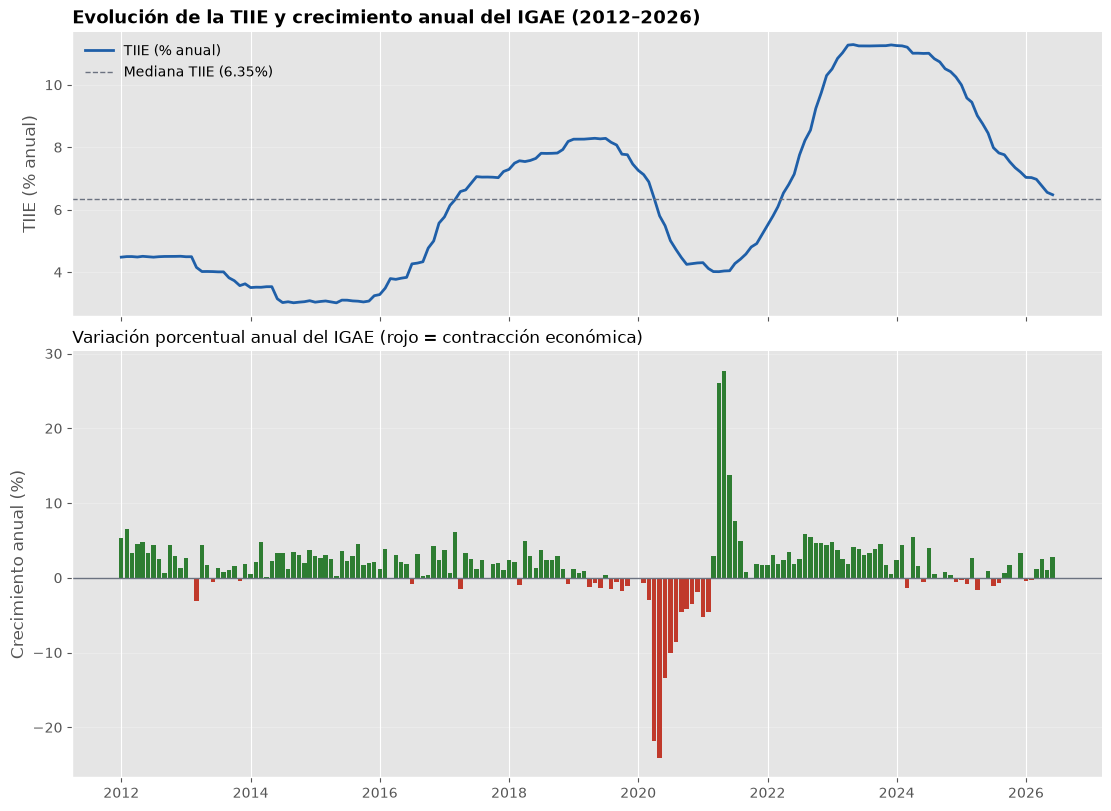

In [8]:
#Gráfica 1
import os
os.makedirs("../docs/pregunta3", exist_ok=True)

AZUL, VERDE, ROJO, GRIS = "#1F5FA8", "#2E7D32", "#C0392B", "#6B7280"

pdf_igae["FECHA"] = pd.to_datetime(pdf_igae["CICLO"] + "-01")
contrac_mask = (pdf_igae["CREC_IGAE_ANUAL"] < 0).to_numpy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 3]}
)

# Panel 1: TIIE
ax1.plot(pdf_igae["FECHA"], pdf_igae["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.axhline(pdf_igae["TIIE_MEDIANA"].iloc[0], color=GRIS, lw=1, ls="--",
            label=f"Mediana TIIE ({pdf_igae['TIIE_MEDIANA'].iloc[0]:.2f}%)")
ax1.set_title("Evolución de la TIIE y crecimiento anual del IGAE (2012–2026)", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("TIIE (% anual)")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: Crecimiento anual del IGAE
colores_igae = [ROJO if v < 0 else VERDE for v in pdf_igae["CREC_IGAE_ANUAL"]]
ax2.bar(pdf_igae["FECHA"], pdf_igae["CREC_IGAE_ANUAL"], width=25, color=colores_igae)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Variación porcentual anual del IGAE (rojo = contracción económica)", loc="left", fontsize=12)
ax2.set_ylabel("Crecimiento anual (%)")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta3/tiie_igae_actividad.png", dpi=150)
plt.show()

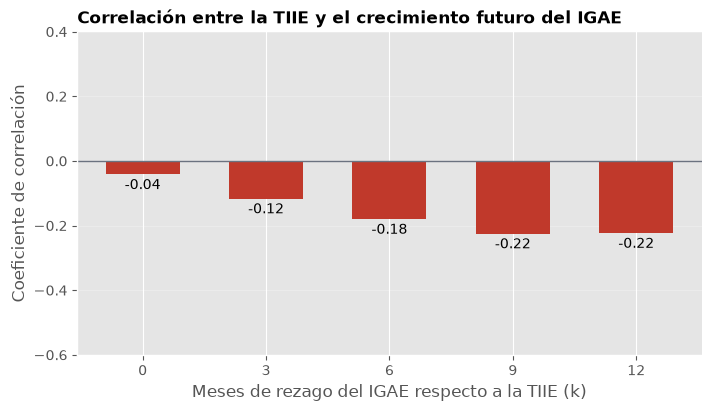

In [9]:
#Gráfica 2
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
colores_corr = [ROJO if v < 0 else AZUL for v in corr_igae["CORRELACION"]]
barras = ax.bar(corr_igae["REZAGO_MESES"].astype(str), corr_igae["CORRELACION"], color=colores_corr, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.axhline(0, color=GRIS, lw=1)
ax.set_ylim(min(-0.6, corr_igae["CORRELACION"].min() - 0.15), max(0.4, corr_igae["CORRELACION"].max() + 0.15))
ax.set_title("Correlación entre la TIIE y el crecimiento futuro del IGAE", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago del IGAE respecto a la TIIE (k)")
ax.set_ylabel("Coeficiente de correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta3/tiie_igae_rezagos.png", dpi=150)
plt.show()

## 5.5. Limitaciones e interpretación prudente

- **Choques exógenos y pandemia de 2020:** La caída abrupta del IGAE en 2020 y su rebote estadístico en 2021 obedecen al choque sanitario y no a movimientos de la TIIE; este evento extremo introduce ruido en las correlaciones lineales de todo el periodo.
- **Correlación no implica causalidad única:** La actividad económica en México responde simultáneamente al ciclo industrial de Estados Unidos, al tipo de cambio, a la inflación y al gasto público; una correlación bivariada no aísla el efecto puro de la TIIE.
- **Sensibilidad a rezagos largos:** La política monetaria suele operar con rezagos de entre 4 y 8 trimestres en economías emergentes; ventanas superiores a 12 meses podrían capturar efectos adicionales fuera del alcance de esta consulta.
- **Cobertura y pérdida inicial de 12 meses:** aunque el Parquet inicia en `2011-01`, el cálculo de variación anual (`LAG(..., 12)`) reduce la muestra efectiva a 174 meses (`2012-01` a `2026-06`).
- **Alcance:** El presente análisis cubre el eslabón *TIIE → IGAE* del mecanismo de transmisión; su impacto posterior sobre recaudación tributaria y gasto público se aborda en las preguntas correspondientes a finanzas públicas.

## 8. Arquitectura aplicada (Etapa D — Integración Pregunta Analítica 3)

Recorrido completo de los datos desde las fuentes hasta el consumo analítico de IGAE + TIIE:

```text
 Fuentes (data/raw)     Procesamiento       Almacenamiento          Consulta (Spark SQL)      Resultado Analítico
┌──────────────────┐   ┌───────────────┐   ┌───────────────────┐   ┌─────────────────────┐   ┌────────────────────┐
│ Banxico (TIIE)   │──▶│ Pipeline      │──▶│ macro_finanzas_   │──▶│ Vistas temporales:  │──▶│ Postura monetaria  │
│ INEGI (IGAE/INPC)│   │ PySpark       │   │ consolidado.      │   │ - macro_igae        │   │ + rezagos (k=0..12)│
│ SHCP (Finanzas)  │   │ (ETL/Clean)   │   │ parquet           │   │ - actividad_        │   │ + gráficas PNG en  │
│                  │   │               │   │ (data/processed/) │   │   monetaria         │   │   docs/pregunta3/  │
└──────────────────┘   └───────────────┘   └───────────────────┘   └─────────────────────┘   └────────────────────┘
```

- **Almacenamiento y reutilización:** El dataset consolidado persiste en disco en formato columnar **Parquet** (`data/processed/macro_finanzas_consolidado.parquet`), lo que permite proyectar únicamente las 3 columnas requeridas (`CICLO`, `TIIE`, `MONTO_IGAE_TOTAL`) mediante *column pruning* sin leer el resto de variables fiscales. Las vistas Spark SQL (`macro_igae`, `actividad_monetaria`) se crean en memoria durante la sesión del notebook sin duplicar archivos procesados.
- **Implementado vs. evolución futura:** Actualmente se utiliza almacenamiento local en Parquet + consultas Spark SQL sobre vistas temporales + exportación estática de figuras PNG. Como evolución futura hacia un entorno productivo tipo **Lakehouse (Delta Lake)**, se podrían versionar las tablas consolidadas y materializar las métricas de crecimiento anual (`CREC_IGAE_ANUAL`) dentro de la capa `processed` del pipeline para que múltiples consumidores las reutilicen sin recalcular funciones de ventana.
- **Incorporación de nuevos datos o correcciones:** Al publicarse nuevos cortes mensuales de INEGI o Banxico (o revisiones de cifras preliminares del IGAE), basta con actualizar los archivos fuente en `data/raw/`, reejecutar `pipeline.py` para regenerar el Parquet consolidado y correr nuevamente el notebook; las aserciones de integridad (`assert`) validan automáticamente que no existan nulos, duplicados ni meses faltantes antes de generar los reportes.

### Reproducibilidad del análisis
1. Asegurarse que exista `data/processed/macro_finanzas_consolidado.parquet` ejecutando el pipeline principal.
2. Abrir `notebooks/reporte_de_proyecto.ipynb` en un entorno con `pyspark`, `pandas` y `matplotlib`.
3. Ejecutar en orden las celdas de la **sección 5 (Pregunta Analítica 3)**; las gráficas se guardarán automáticamente en `docs/pregunta3/`.

### 6. 

In [14]:
### PONER CÓDIGO

### 7.

In [15]:
### PONER CÓDIGO

### 8.

In [16]:
### PONER CÓDIGO